# Expirement with running multiple ASP programs multiple times

### Variables

In [155]:
import clingo
import time
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

def load_program(puzzle, gen=False):
    '''
        Load the necessary lp files to load a complete puzzle:
        - with base file
        - with puzzle world
        - with clues
        and create a clingo control variable
    '''
    ctl = clingo.Control(["0", "--stats=2", "--warn=no-atom-undefined"])
    ctl.load('../solve-experiment.lp')
    ctl.load('../base-rules.lp')
    if gen:
        ctl.load(f'../autogenerated_puzzles/puzzles/puzzle{puzzle}.lp')
        ctl.load(f'../autogenerated_puzzles/clues/clues{puzzle}.lp')
    else:
        ctl.load(f'../puzzles/puzzle{puzzle}.lp')
        ctl.load(f'../clues/clues{puzzle}.lp')
    ground_start = time.perf_counter()
    ctl.ground([("base", [])])
    ground_time = time.perf_counter() - ground_start
    return ctl, ground_time
 
def solve_puzzle(puzzle, gen=False, count=False):
    '''
        Solve a clingo program by loading an lp file.
        Output atoms
        Output all solutions
    '''
    ctl, ground_time = load_program(puzzle, gen)
    def on_model(model):
        print(model.symbols(shown=True))
    with ctl.solve(on_model=on_model, yield_=True) as handle:
        models = list(handle)
        result = handle.get()
        stats = ctl.statistics
        solve_time = stats['summary']['times']['solve']
        grid_size = ctl.get_const('n').number

        # extract number of clues:
        atoms = ctl.symbolic_atoms
        clue_count = sum(1 for atom in atoms if atom.symbol.name == 'clue')
    if count:
        print(f'Number of models: {len(models)}')
        
    print(result)
    print("Satisfiable:", result.satisfiable)
    print("Unsatisfiable:", result.unsatisfiable)
    print("Unknown:", result.unknown)
    return result, ground_time, solve_time, grid_size, clue_count, models

### Run experiment
- epoch is one run of all available puzzles
- type 'M' puzzles are manually taken from Murdoku book 1
- type 'A' puzzles are automatically generated with our Murdoku-generator
- statistics like grounding time, solving time, total time, grid size and number of clues are store per puzzle per epoch, these can later be used for analysis


In [171]:
# number of runs for experiment
epochs = 5


puzzles = list(Path('../puzzles').glob("puzzle*.lp"))
puzzles_gen = list(Path('../autogenerated_puzzles/puzzles').glob('puzzle*.lp'))
puzzles.extend(puzzles_gen)
results = []
for i in range(epochs):
    print(f'start epoch {i+1}/{epochs}')

    for p in puzzles:
        puzzle_id = p.stem.removeprefix("puzzle")
        puzzle_type = puzzle_id[0]
        puzzle_num = int(puzzle_id.split('-')[1])
        print(f'Puzzle #{puzzle_id}, {puzzle_type}, {puzzle_type == 'A'}')
        result, ground_time, solve_time, grid_size, clue_count, models = solve_puzzle(puzzle_id, puzzle_type == 'A')
        results.append({
            'epoch': i,
            'puzzle': puzzle_num,
            'type': puzzle_type, # automated puzzles with 'type': 'A' manual with 'M', comes from file names.
            'ground_time': ground_time,
            'solve_time': solve_time,
            'total_time': ground_time + solve_time,
            'grid_size': grid_size + 1,
            'clue_count': clue_count,
            'solve_state': result.satisfiable,
            'num_solutions': len(models)
        })

    print(f'end epoch {i+1}/{epochs}')
    print()
    print('----------------------------------')
    print()

print('ground times:')
for i in range(epochs):
    print(f'epoch {i+1}:') 
    print(f'ground_times: {[x['ground_time'] for x in results if x['epoch'] == i]}')
    print(f'solve_times: {[x['solve_time'] for x in results if x['epoch'] == i]}')
    print(f'total_times: {[x['total_time'] for x in results if x['epoch'] == i]}')
    print(f'grid_sizes: {[x['grid_size'] for x in results if x['epoch'] == i]}')
    print()

start epoch 1/5
Puzzle #M9-45, M, False
[at(alphonse,4,5), at(bernard,3,4), at(carol,1,7), at(daisy,7,6), at(emily,0,3), at(frank,8,1), at(george,2,0), at(henry,5,8), at(victor,6,2), murderer(frank), clue(alphonse,in,mainfloor), clue(alphonse,east_of,emily), clue(alphonse,south_of,bernard), clue(bernard,next_to_with_someone_else,plant), clue(daisy,only_one_on,chair), clue(emily,in_row,0), clue(frank,next_to,tv), clue(george,next_to,table), clue(george,next_to,chair), clue(henry,only_one_on,window), clue(carol,alone), clue(no_empty_room)]
SAT
Satisfiable: True
Unsatisfiable: False
Unknown: False
Puzzle #M6-1, M, False
[at(alphonse,0,1), at(bonnie,4,0), at(carol,1,2), at(daniel,2,4), at(emily,5,5), at(victor,3,3), murderer(emily), clue(alphonse,on,window), clue(bonnie,in,hallway), clue(carol,on,carpet), clue(daniel,on,bed), clue(emily,next_to,plant)]
SAT
Satisfiable: True
Unsatisfiable: False
Unknown: False
Puzzle #M8-10, M, False
[at(alphonse,7,6), at(bernard,1,7), at(carol,6,2), at(dai

### Analyze
- check for unsatisfiable puzzles
- check for puzzles with multiple solutions
- convert results to Pandas DataFrame for easy evaluation
- Compare performance between puzzles
- Compare performance between grid sizes
- Compare performance between number of clues
- Compare performance between combination of grid size and number of clues

In [172]:
df = pd.DataFrame(results)
df.head()


,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,solve_state,num_solutions
0,0,45,M,0.312093,0.050992,0.363085,9,12,True,1
1,0,1,M,0.022596,0.000105,0.022701,6,5,True,1
2,0,10,M,0.120717,0.009197,0.129914,8,9,True,1
3,0,24,M,0.112222,0.007770,0.119992,8,10,True,1
4,0,21,M,0.020848,0.001580,0.022428,6,6,True,1


In [173]:
(~df['solve_state']).sum()

np.int64(0)

In [174]:
multi_solutions = df[(df['num_solutions'] > 1) & (df['epoch'] == 0)]
multi_solutions

,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,solve_state,num_solutions


In [150]:
df.groupby('puzzle')[['ground_time', 'solve_time', 'total_time']].mean()

,ground_time,solve_time,total_time
puzzle,,,
0,0.022107,0.000716,0.022824
1,0.023502,0.002037,0.025538
2,0.025256,0.001056,0.026312
3,0.025745,0.001360,0.027106
4,0.024455,0.001767,0.026221
...,...,...,...
95,0.023934,0.002918,0.026852
96,0.024569,0.001742,0.026311
97,0.023870,0.002169,0.026039


In [151]:
df.groupby('grid_size')[['ground_time', 'solve_time', 'total_time']].mean()

,ground_time,solve_time,total_time
grid_size,,,
4,0.003464,0.000164,0.003628
5,0.009383,0.000559,0.009943
6,0.024249,0.001706,0.025955
7,0.060163,0.005302,0.065465
8,0.123457,0.009441,0.132898
9,0.282237,0.043901,0.326138


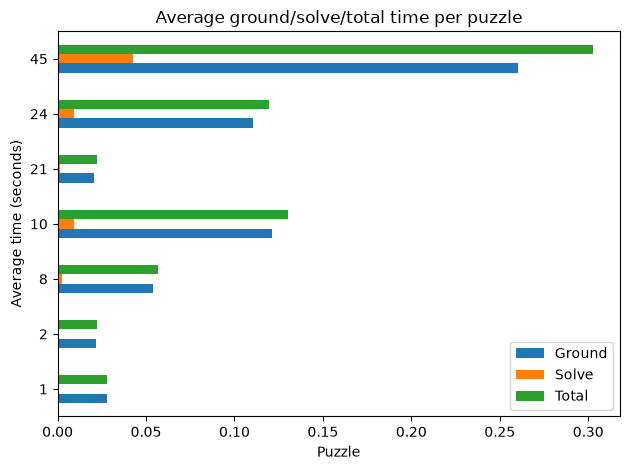

In [ ]:
# df.groupby('puzzle')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

# plt.xlabel('Puzzle')
# plt.ylabel('Average time (seconds)')
# plt.title('Average ground/solve/total time per puzzle')
# plt.legend(['Ground', 'Solve', 'Total'])
# plt.tight_layout()
# plt.show()

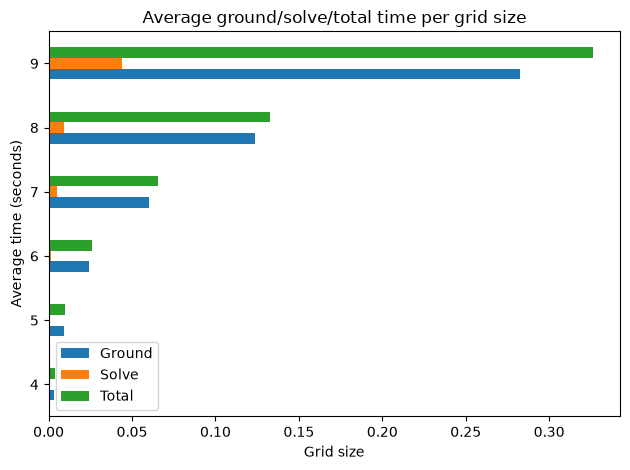

In [152]:
df.groupby('grid_size')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.xlabel('Grid size')
plt.ylabel('Average time (seconds)')
plt.title('Average ground/solve/total time per grid size')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

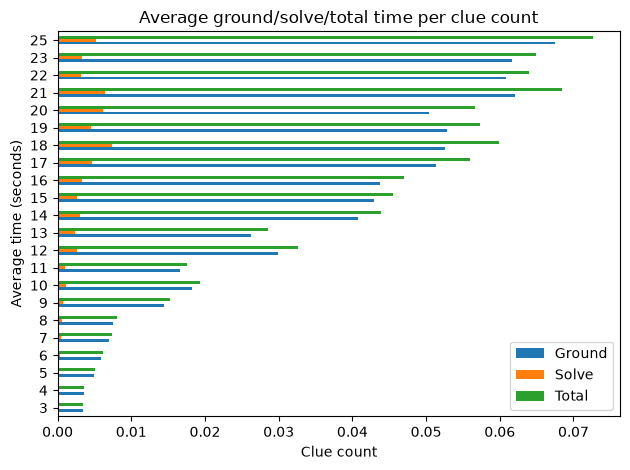

In [153]:
df.groupby('clue_count')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.xlabel('Clue count')
plt.ylabel('Average time (seconds)')
plt.title('Average ground/solve/total time per clue count')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

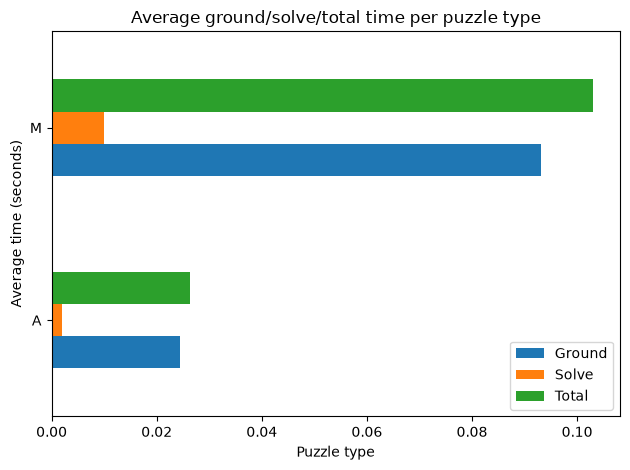

In [154]:
df.groupby('type')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.xlabel('Puzzle type')
plt.ylabel('Average time (seconds)')
plt.title('Average ground/solve/total time per puzzle type')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()